# Model 4 - Diffusion refiner
Run the setup cell first, then **Run all**. About 1-2 hours on a T4.
Needs `coarse_cache.pt` from notebook 03.

In [1]:
!pip install -q librosa soundfile num2words


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: C:\Users\INTEL\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [2]:
import sys, torch
ROOT = r"C:\Users\INTEL\Downloads\voice_cloning_v2_1\voice_cloning_v2_1"
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE")

GPU: NVIDIA GeForce RTX 4070


[diffusion] starting fresh
[diffusion] epoch 1/60  train=0.1510  val=0.0659  (35s)  * best
[diffusion] epoch 2/60  train=0.0548  val=0.0502  (33s)  * best
[diffusion] epoch 3/60  train=0.0519  val=0.0483  (33s)  * best
[diffusion] epoch 4/60  train=0.0507  val=0.0474  (35s)  * best
[diffusion] epoch 5/60  train=0.0494  val=0.0468  (36s)  * best
[diffusion] epoch 6/60  train=0.0491  val=0.0464  (34s)  * best
[diffusion] epoch 7/60  train=0.0493  val=0.0462  (34s)  * best
[diffusion] epoch 8/60  train=0.0484  val=0.0460  (34s)  * best
[diffusion] epoch 9/60  train=0.0487  val=0.0458  (33s)  * best
[diffusion] epoch 10/60  train=0.0483  val=0.0457  (33s)  * best
[diffusion] epoch 11/60  train=0.0481  val=0.0455  (35s)  * best
[diffusion] epoch 12/60  train=0.0481  val=0.0454  (33s)  * best
[diffusion] epoch 13/60  train=0.0478  val=0.0454  (33s)  * best
[diffusion] epoch 14/60  train=0.0476  val=0.0453  (33s)  * best
[diffusion] epoch 15/60  train=0.0479  val=0.0452  (35s)  * best
[diffus

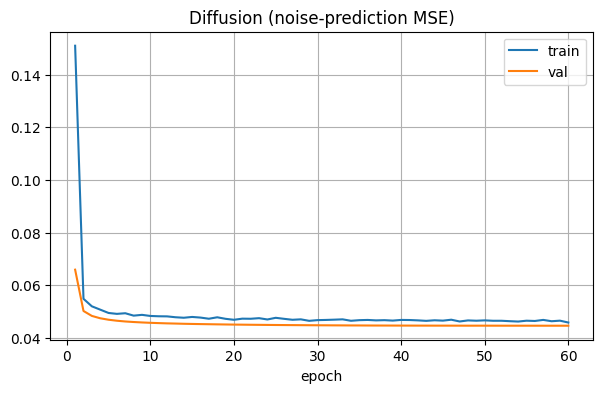

In [3]:
from vc_lib import train_diffusion
from vc_lib.common import plot_history

hist = train_diffusion.train(ROOT, epochs=60, batch_size=32, lr=2e-4)
plot_history(hist, ['train', 'val'], 'Diffusion (noise-prediction MSE)')

## Coarse vs refined vs ground truth
The refined mel should look sharper than the coarse one. Judge by sharpness and listening, not by the loss.

c:\Users\INTEL\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


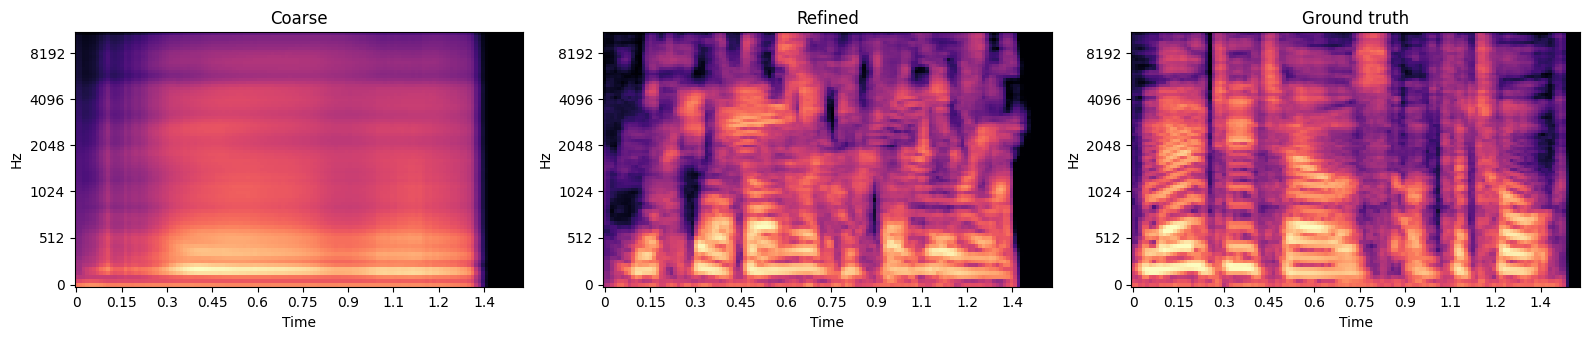

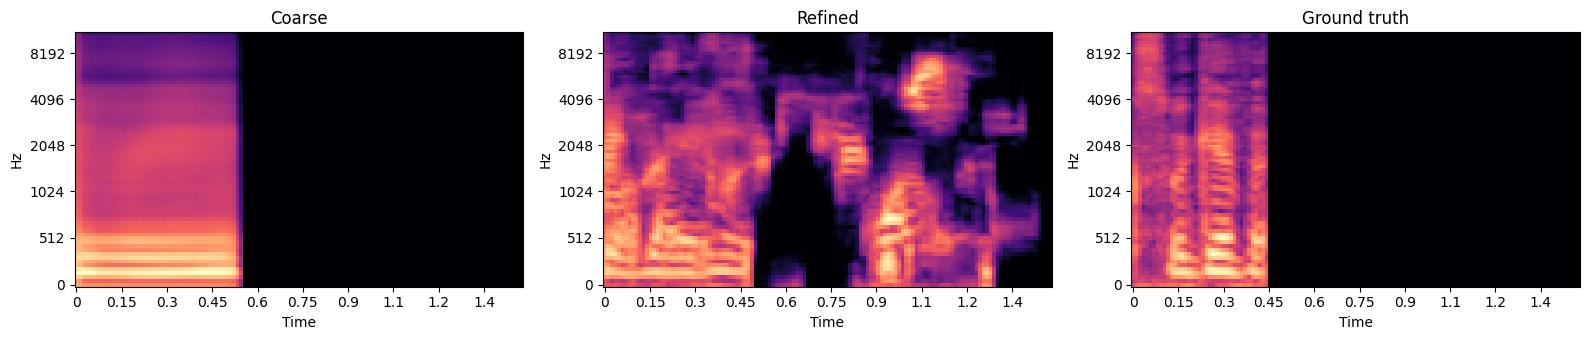

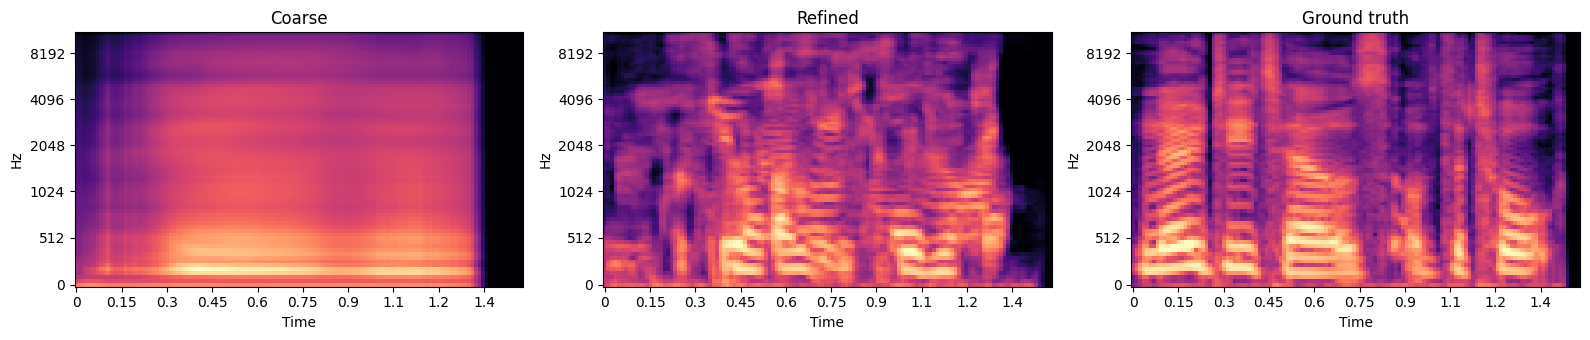

Sharpness  coarse 0.0112 | refined 0.0413 | truth 0.0379


In [4]:
import torch, matplotlib.pyplot as plt, librosa.display
from vc_lib import train_diffusion
from vc_lib.common import paths, load_cache, tload, device, SR
p = paths(ROOT); C = load_cache(p); CC = tload(p['coarse'])
net = train_diffusion.load_diffusion(ROOT); sch = train_diffusion.Schedule(200)
rows = C['idx']['val'][:3]
coarse = CC['coarse'][rows].float().unsqueeze(1).to(device); spk = CC['spk_emb'][rows].to(device)
ref = train_diffusion.ddim_sample(net, sch, coarse, spk, steps=50, cfg=1.5, seed=0)
for r, i in enumerate(rows.tolist()):
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.5))
    for a, d, t in zip(ax, [coarse[r], ref[r], C['mels'][i]], ['Coarse', 'Refined', 'Ground truth']):
        librosa.display.specshow(d.squeeze().float().cpu().numpy(), ax=a, sr=SR, hop_length=256, x_axis='time', y_axis='mel'); a.set_title(t)
    plt.tight_layout(); plt.show()
gt = C['mels'][rows].float().unsqueeze(1)
sharp = lambda m: m.diff(dim=2).abs().mean().item()
print(f'Sharpness  coarse {sharp(coarse.cpu()):.4f} | refined {sharp(ref.cpu()):.4f} | truth {sharp(gt):.4f}')